In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

In [7]:
data = pd.read_csv('./DataSets/linear-reg_data.csv')

In [8]:
# Input
X = np.array([1, 2, 3, 4, 5]).reshape(-1, 1)
X

array([[1],
       [2],
       [3],
       [4],
       [5]])

In [ ]:
# Output Marks
y = np.array([40, 50, 50, 60, 70])
y

array([40, 50, 50, 60, 70])

In [ ]:
# Create Training Model

model = LinearRegression()
model.fit(X, y)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[7.]
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,33
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](1,)",[3.16]


In [ ]:
# Display the Regression Parameter

print('Intercept: ', model.intercept_)
print('Slope: ', model.coef_[0])

Intercept:  33.0
Slope:  7.0


In [ ]:
# Predict marks for six study hours

new_data = np.array([[6]])
predicted_mark = model.predict(new_data)
predicted_mark

array([75.])

In [ ]:
print('Predicted Mark: ', predicted_mark[0])

Predicted Mark:  75.0


In [ ]:
# Predictions for the Original Observations

y_pred = model.predict(X)
y_pred



array([40., 47., 54., 61., 68.])

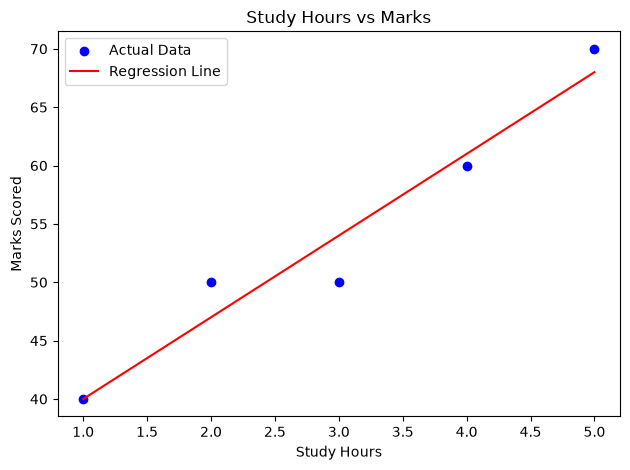

In [ ]:
plt.scatter(X, y, color='blue', label='Actual Data')
plt.plot(X, y_pred, color='red', label='Regression Line')

plt.title('Study Hours vs Marks')

plt.legend()
plt.xlabel('Study Hours')
plt.ylabel('Marks Scored')

plt.tight_layout()
plt.grid(False)
plt.show()

#### Evaluating Python Model

In [ ]:
import numpy as np
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

In [ ]:
mae = mean_absolute_error(y, y_pred)
mse = mean_squared_error(y, y_pred)

rmse = np.sqrt(mse)
r2 = r2_score(y, y_pred)

In [ ]:
print('MAE: ', mae)
print('MSE: ', mse)
print('RMSE: ', rmse)
print('R-Squared Error: ', r2_score)

MAE:  2.0
MSE:  6.0
RMSE:  2.449489742783178
R-Squared Error:  <function r2_score at 0x000002A2F91B7A00>


#### Train-Test Split Example

In [55]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [ ]:
data = {
    "Study_Hours" : [1, 2, 3, 4, 5, 6, 7, 8, 9, 10],
    "Marks" : [32, 38, 43, 50, 54, 61, 68, 73, 81, 88]
}

In [ ]:
df = pd.DataFrame(data)
df

,Study_Hours,Marks
0,1,32
1,2,38
2,3,43
3,4,50
4,5,54
5,6,61
6,7,68
7,8,73
8,9,81
9,10,88


In [ ]:
X = df[['Study_Hours']]
y = df['Marks']

X, y

(   Study_Hours
 0            1
 1            2
 2            3
 3            4
 4            5
 5            6
 6            7
 7            8
 8            9
 9           10,
 0    32
 1    38
 2    43
 3    50
 4    54
 5    61
 6    68
 7    73
 8    81
 9    88
 Name: Marks, dtype: int64)

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [ ]:
model = LinearRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

In [ ]:
print('Intercept: ', model.intercept_)
print('Slope: ', model.coef_[0])
print('Actual Values: ', y_test.values)
print('Predicted Values: ', y_pred)

Intercept:  24.724137931034484
Slope:  6.163793103448276
Actual Values:  [81 38]
Predicted Values:  [80.19827586 37.05172414]


In [ ]:
print('MAE: ', mean_absolute_error(y_test, y_pred))
print('MSE: ', mean_squared_error(y_test, y_pred))
print('RMSE: ', np.sqrt(mean_squared_error(y_test, y_pred)))
print('R-Squared Error: ', r2_score(y_test, y_pred))

MAE:  0.875
MSE:  0.7709943519619504
RMSE:  0.8780628405541089
R-Squared Error:  0.9983320836085193


#### Multiple Linear Regression

In [ ]:
import pandas as pd
from sklearn.linear_model import LinearRegression

In [ ]:
data = {
    "Study_Hours" : [2, 3, 4, 5, 6, 7, 8, 9],
    "Attendance" : [60, 65, 70, 75, 80, 85, 90, 95],
    "Assignment_Score" : [50, 55, 58, 65, 70, 74, 80, 88],
    "Final_Marks" : [42, 48, 54, 61, 67, 73, 81, 89]
}
data

{'Study_Hours': [2, 3, 4, 5, 6, 7, 8, 9],
 'Attendance': [60, 65, 70, 75, 80, 85, 90, 95],
 'Assignment_Score': [50, 55, 58, 65, 70, 74, 80, 88],
 'Final_Marks': [42, 48, 54, 61, 67, 73, 81, 89]}

In [ ]:
df = pd.DataFrame(data)
df

,Study_Hours,Attendance,Assignment_Score,Final_Marks
0,2,60,50,42
1,3,65,55,48
2,4,70,58,54
3,5,75,65,61
4,6,80,70,67
5,7,85,74,73
6,8,90,80,81
7,9,95,88,89


In [ ]:
X = df[["Study_Hours", "Attendance", "Assignment_Score"]]
X

,Study_Hours,Attendance,Assignment_Score
0,2,60,50
1,3,65,55
2,4,70,58
3,5,75,65
4,6,80,70
5,7,85,74
6,8,90,80
7,9,95,88


In [ ]:
y = df["Final_Marks"]
y

0    42
1    48
2    54
3    61
4    67
5    73
6    81
7    89
Name: Final_Marks, dtype: int64

In [ ]:
model = LinearRegression()
model.fit(X, y)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](3,)","[0.13,0.66,0.61]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](3,)","['Study_Hours','Attendance','Assignment_Score']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-28.32
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,3
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(2)


In [ ]:
print('Intercept: ', model.intercept_)

Intercept:  -28.31652806652808


In [ ]:
print('Slope: ', model.coef_)
# print('Slope: ', (x for x in model.coef_.data))
coefficient_table = pd.DataFrame( {
    "Feature":  X.columns,
    "Coefficient" : model.coef_
})
coefficient_table

Slope:  [0.13141026 0.65705128 0.60810811]


,Feature,Coefficient
0,Study_Hours,0.131410
1,Attendance,0.657051
2,Assignment_Score,0.608108


In [ ]:
new_student = pd.DataFrame({
    "Study_Hours": [6],
    "Attendance" : [82],
    "Assignment_Score" : [72]
})
new_student

,Study_Hours,Attendance,Assignment_Score
0,6,82,72


In [ ]:
prediction = model.predict(new_student)
print('Predicted Final Marks: ', prediction[0])

Predicted Final Marks:  70.13392238392238


#### Using DataSet

In [ ]:
import pandas as pd
import numpy as np

In [ ]:
import matplotlib.pyplot as plt

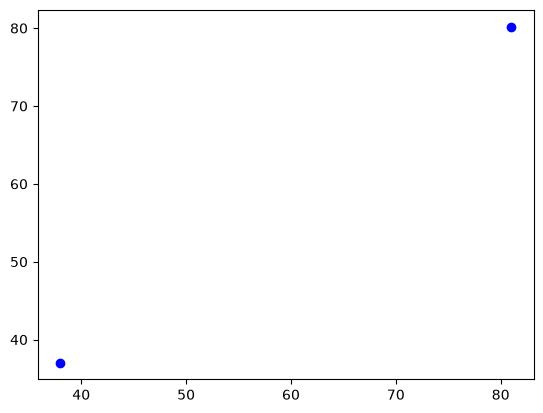

In [ ]:
plt.scatter(y_test, y_pred, color="blue")

In [ ]:
minimum = min(y_test.min(), y_pred.min())
maximum = max(y_test.max(), y_pred.max())

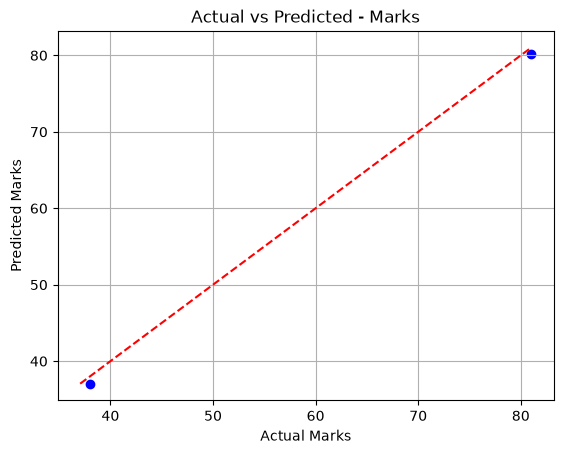

In [ ]:
plt.scatter(y_test, y_pred, color="blue")

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    color='red',
    linestyle='--',
)
plt.xlabel('Actual Marks'),
plt.ylabel('Predicted Marks')
plt.title('Actual vs Predicted - Marks')
plt.grid()

#### Residual Plot

In [ ]:
residuals = y_test - y_pred
residuals

8    0.801724
1    0.948276
Name: Marks, dtype: float64

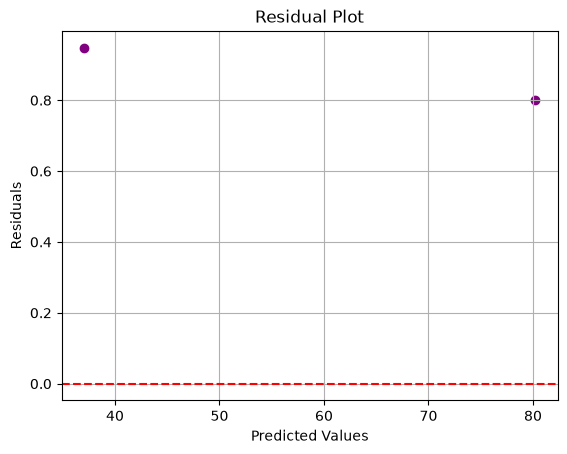

In [ ]:
plt.scatter(y_pred, residuals, color='purple')
plt.axhline(y=0, color='red', linestyle='--')

plt.xlabel('Predicted Values')
plt.ylabel('Residuals')
plt.title('Residual Plot')
plt.grid()
plt.show()

In [ ]:
import pandas as pd

In [29]:
data = {
    "Size": [800, 1000, 1200, 1500, 1800],
    "Location" : ["Rural", "Urban", "Rural", "Urban", "Urban"],
    "Price" : [30, 50, 42, 72, 85]
}
data

{'Size': [800, 1000, 1200, 1500, 1800],
 'Location': ['Rural', 'Urban', 'Rural', 'Urban', 'Urban'],
 'Price': [30, 50, 42, 72, 85]}

In [30]:
df = pd.DataFrame(data)
df

,Size,Location,Price
0,800,Rural,30
1,1000,Urban,50
2,1200,Rural,42
3,1500,Urban,72
4,1800,Urban,85


In [31]:
df_encoded = pd.get_dummies(
    df, columns=["Location"], drop_first=True, dtype=int
)
df_encoded

,Size,Price,Location_Urban
0,800,30,0
1,1000,50,1
2,1200,42,0
3,1500,72,1
4,1800,85,1


In [40]:
X = df_encoded[['Size', 'Location_Urban']]
y = df_encoded['Price']

In [41]:
X, y

(   Size  Location_Urban
 0   800               0
 1  1000               1
 2  1200               0
 3  1500               1
 4  1800               1,
 0    30
 1    50
 2    42
 3    72
 4    85
 Name: Price, dtype: int64)

In [42]:
model = LinearRegression()
model.fit(X, y)


LinearRegression()

In [46]:
print('Coefficient or Slope: ', model.coef_)
print('Intercept: ', model.intercept_)

Coefficient or Slope:  [ 0.04106557 15.20491803]
Intercept:  -5.065573770491781


In [49]:
new_data = pd.DataFrame( {
    'Size' : [990],
    'Location_Urban' : [0]
})

new_data

,Size,Location_Urban
0,990,0


In [52]:
model.predict(new_data)[0]

35.589344262295086

In [57]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_split=0.2, random_state=42)

TypeError: train_test_split() got an unexpected keyword argument 'test_split'